1. Load dataset

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import f1_score, roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

X, y = load_breast_cancer(return_X_y=True)

2. Decision Tree, Random Forest and Gradient Boosting

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

for model in models.values():
    model.fit(X_train, y_train)

3. Random Forest hyperparameters

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2],
    "min_samples_split":[2,5,10],
    "max_features":["sqrt","log2"]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)

print("Best combination:", grid.best_params_)
models["Random Forest (tuned)"] = grid.best_estimator_

Best combination: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


4. ROC-AUC and F1 for all models

In [10]:
rows = []
for name, model in models.items():
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        "F1": f1_score(y_test, model.predict(X_test)),
    })

pd.DataFrame(rows).set_index("Model").round(4)

,ROC-AUC,F1
Model,,
Decision Tree,0.9157,0.9286
Random Forest,0.9937,0.9655
Gradient Boosting,0.9907,0.9660
Random Forest (tuned),0.9924,0.9655


Random forest and Gradient boosting are somewhat tied. Tuning didn't help, it has the same F1 score as the untuned random forest and ROC-AUC does not seem significantly different. I am guessing it's because the dataset is simple. 

5. ROC curves

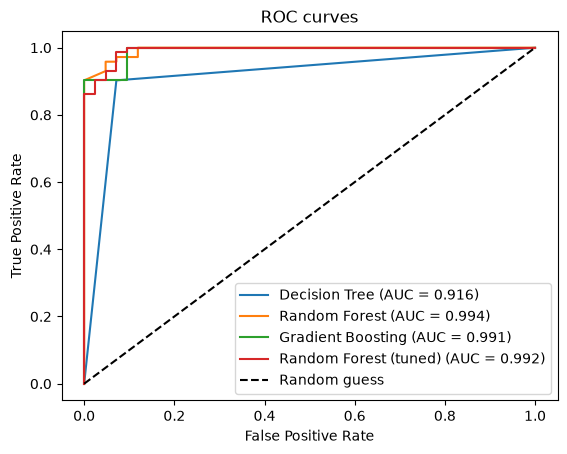

In [11]:
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.show()